In [1]:
!pip install pandas numpy matplotlib seaborn nltk scikit-learn


Defaulting to user installation because normal site-packages is not writeable


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#re is Regular Expressions
import re
import nltk

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer #TF-IDF    TF = Term Frequency.IDF = Inverse Document Frequency.(how imp is the word)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ranganatha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
import pandas as pd

# Load the uploaded dataset into df
df = pd.read_csv('IMDB Dataset.csv')

# Number of rows and columns
print(df.shape)

# Column names
print(df.columns)

# Dataset information
df.info()

# Statistical summary
df.describe()

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print(df.duplicated().sum())

(50000, 2)
Index(['review', 'sentiment'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
review       0
sentiment    0
dtype: int64
418


In [5]:
#Remove missing and duplicate records:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print(df.shape)

(49582, 2)


In [6]:
print(df['sentiment'].value_counts())

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


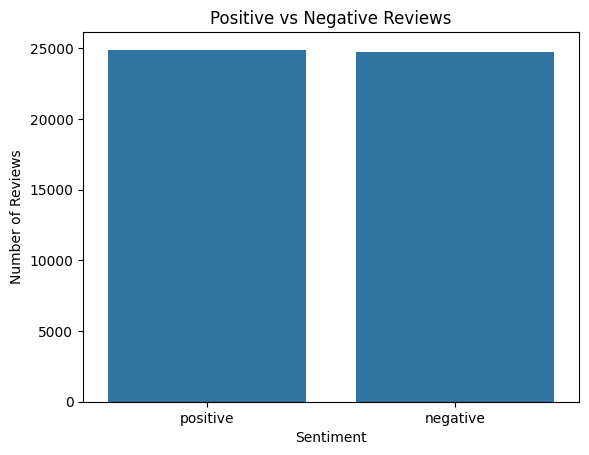

In [7]:
sns.countplot(data=df, x='sentiment')

plt.title('Positive vs Negative Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

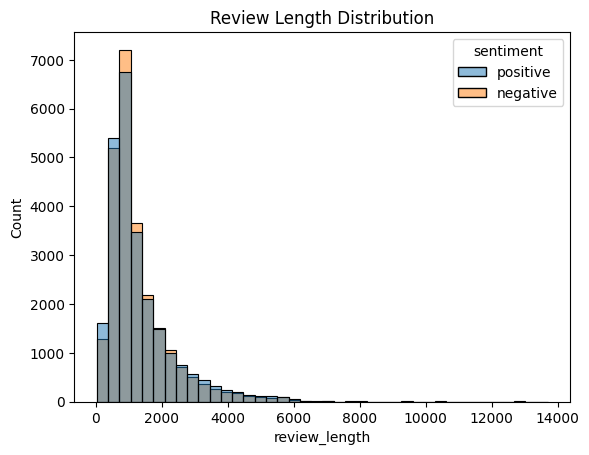

In [8]:
df['review_length'] = df['review'].apply(len)

sns.histplot(
    data=df,
    x='review_length',
    hue='sentiment',
    bins=40
)

plt.title('Review Length Distribution')
plt.show()

In [23]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [24]:
df['cleaned_review'] = df['review'].apply(clean_text)

df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,One of the other reviewers has mentioned that ...,one reviewers mentioned watching oz episode yo...
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,basically theres family little boy jake thinks...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter matteis love time money visually stunni...


In [25]:
#This code removes "not", "no", and "nor" from the stopwords set so that these words are not deleted during text cleaning.
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

In [26]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)#This tells Python to consider both individual words and combinations of two consecutive words.
)
#Converting reviews into numbers
X = tfidf.fit_transform(df['cleaned_review'])

y = df['sentiment']

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)#training data dimensions
print("X_test shape:", X_test.shape)#testing data dimensions

print("Train-test split completed!")

X_train shape: (39665, 5000)
X_test shape: (9917, 5000)
Train-test split completed!


In [28]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [35]:
y_pred = model.predict(X_test)

print(y_pred[:10])

['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative']


In [30]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 88.67601089039024 %


In [31]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      4940
    positive       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



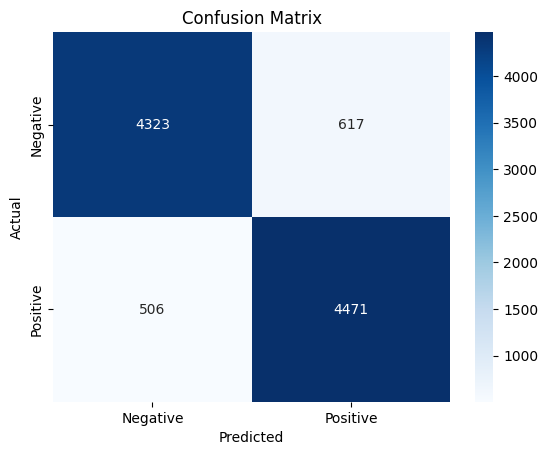

In [32]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['negative', 'positive']
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [33]:
def predict_sentiment(review):

    cleaned = clean_text(review)

    vectorized = tfidf.transform([cleaned])

    prediction = model.predict(vectorized)

    return prediction[0]


print(predict_sentiment(

    "This product is amazing and I absolutely love it"
))

print(predict_sentiment(
    "Very poor quality. I am completely disappointed"
))

positive
negative
